# Curl-curl problems with Nedelec elements

This tutorial combines a Maxwell-type demo of
[DOLFINx](https://docs.fenicsproject.org/dolfinx/main/python/demos.html) with the
electromagnetics chapter of the [FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/).
In the first part we solve the 3D curl-curl problem

$$ \nabla\times\nabla\times u + u = f \ \text{in } \Omega = (0,1)^3, \qquad u\times n = g\times n \ \text{on } \partial\Omega $$

with Nedelec elements of the first kind, whose tangential trace is continuous across
elements.  In the second part we compute the magnetic field of a 2D device with coils
and an iron core.

## Part 1: manufactured solution

The weak form is: find $u \in H(\mathrm{curl})$ with the prescribed tangential trace such
that

$$ \int_\Omega \nabla\times u\cdot\nabla\times v + u\cdot v \,dx = \int_\Omega f\cdot v\,dx \qquad \forall v \in H_0(\mathrm{curl}) . $$

The tangential Dirichlet condition is essential and imposed with `DirichletBC` on the
`N1curl` space (degree 1 is the lowest order element, as in Firedrake).  The front end follows the Firedrake API.  We use
$u_e = (\sin\pi y,\ \sin\pi z,\ \sin\pi x)$, for which $f = \nabla\times\nabla\times u_e + u_e$ is
computed by UFL.

In [1]:
from ngsufl import *
import numpy as np

def exact(mesh, kind):
    x, y, z = SpatialCoordinate(mesh)
    if kind == "inhomogeneous":
        return as_vector((sin(pi * y), sin(pi * z), sin(pi * x)))
    # tangential trace vanishes on the whole boundary
    return as_vector((sin(pi * y) * sin(pi * z),
                      sin(pi * z) * sin(pi * x),
                      sin(pi * x) * sin(pi * y)))

def solve_maxwell(n, k, kind="inhomogeneous"):
    mesh = UnitCubeMesh(n, n, n)
    V = FunctionSpace(mesh, "N1curl", k)
    u, v = TrialFunction(V), TestFunction(V)
    u_e = exact(mesh, kind)
    f = curl(curl(u_e)) + u_e

    a = (inner(curl(u), curl(v)) + inner(u, v)) * dx
    L = inner(f, v) * dx
    uh = Function(V, name="u")
    solve(a == L, uh, bcs=DirichletBC(V, u_e, "on_boundary"),
          solver_parameters={"ksp_type": "preonly", "pc_type": "lu"})
    return u_e, uh

u_e, uh = solve_maxwell(4, 2)
print("dofs:", uh.function_space().dim())
print("L2 error   :", errornorm(u_e, uh))
print("curl error :", norm(curl(u_e - uh)))

dofs: 2936
L2 error   : 0.02320919620344625
curl error : 0.06701646431652461


## Convergence

The method is optimal in $H(\mathrm{curl})$: with degree $k$ both
$\|u-u_h\|_{L^2}$ and $\|\nabla\times(u-u_h)\|_{L^2}$ should converge as $h^k$.
For the second kind of space one would use `"N2curl"`.  NGSolve provides these spaces for
arbitrary degrees, in 2D and 3D and on all element shapes.

We run two variants.  The first has non-zero tangential data as above.  In the second the exact
field has zero tangential trace, so the boundary condition is exact.

In [2]:
def rates(errs, hs):
    return [np.log(errs[i] / errs[i + 1]) / np.log(hs[i] / hs[i + 1]) for i in range(len(errs) - 1)]

for kind in ["inhomogeneous", "zero trace"]:
    print(kind)
    for k, ns in [(1, [2, 4, 8, 16]), (2, [2, 4, 8])]:
        hs = [1 / n for n in ns]
        e0, e1 = [], []
        for n in ns:
            ue, uh = solve_maxwell(n, k, kind)
            e0.append(errornorm(ue, uh))
            e1.append(norm(curl(ue - uh)))
        print(f"  k={k}  L2  :", " ".join(f"{e:.2e}" for e in e0), "  rates", " ".join(f"{r:.2f}" for r in rates(e0, hs)))
        print(f"       curl:", " ".join(f"{e:.2e}" for e in e1), "  rates", " ".join(f"{r:.2f}" for r in rates(e1, hs)))

inhomogeneous


  k=1  L2  : 5.13e-01 2.73e-01 1.38e-01 6.93e-02   rates 0.91 0.98 1.00
       curl: 1.35e+00 6.89e-01 3.46e-01 1.73e-01   rates 0.97 0.99 1.00


  k=2  L2  : 9.16e-02 2.32e-02 5.84e-03   rates 1.98 1.99
       curl: 2.62e-01 6.70e-02 1.68e-02   rates 1.97 1.99
zero trace


  k=1  L2  : 5.02e-01 2.90e-01 1.50e-01 7.59e-02   rates 0.79 0.95 0.99
       curl: 1.91e+00 1.06e+00 5.41e-01 2.71e-01   rates 0.85 0.97 0.99


  k=2  L2  : 1.32e-01 3.63e-02 9.44e-03   rates 1.86 1.94
       curl: 5.26e-01 1.47e-01 3.77e-02   rates 1.84 1.96


Both errors converge with the optimal order $k$, with and without boundary data.  The
tangential data enters through NGSolve's canonical interpolation, which commutes with the
curl.  An $L^2$ projection of the data into the space would lose one order in the curl.

A look at the solution on the boundary of the cube; the plot shows the magnitude of the
degree-2 field.  `plot` is an ngsufl convenience for 3D results (Firedrake would write a VTK file).

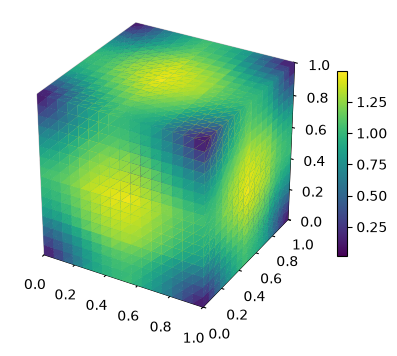

In [3]:
import matplotlib.pyplot as plt

u_e, uh = solve_maxwell(4, 2)
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(projection="3d")
plot(uh, ax=ax);

## Part 2: magnetostatics of a coil and iron core

For currents flowing in the $z$ direction, the magnetic vector potential has only a
$z$ component, $A = (0,0,A_z)$, which is a scalar $H^1$ function.  With the
permeability $\mu$ and the current density $J_z$,

$$ -\nabla\cdot\big(\mu^{-1}\nabla A_z\big) = J_z \ \text{in } \Omega, \qquad A_z = 0 \ \text{on the outer boundary}, $$

and the flux density is $B = (\partial_y A_z, -\partial_x A_z)$, i.e. `curl(A_z)` of the
scalar in UFL.  The geometry is a disk of air with two coil cross sections (opposite
current directions) and a vertical iron bar between them.  It is built with
`netgen.occ`; the names given to the faces become material names, which the integration
measures `dx("iron")`, `dx("coil_p")` address directly.  Names of materials and boundaries are an
ngsufl extra (Firedrake would use the numbers of the cell and facet markers; ids here are the
1-based NGSolve indices).  Curved boundaries are represented by a cubic geometry map.

In [4]:
from netgen.occ import Circle, MoveTo, Glue, OCCGeometry

disk = Circle((0, 0), 1.0).Face()
disk.edges.name = "rim"
coil_p = MoveTo(0.4, -0.3).Rectangle(0.2, 0.6).Face(); coil_p.faces.name = "coil_p"
coil_m = MoveTo(-0.6, -0.3).Rectangle(0.2, 0.6).Face(); coil_m.faces.name = "coil_m"
iron = MoveTo(-0.1, -0.45).Rectangle(0.2, 0.9).Face(); iron.faces.name = "iron"
air = disk - coil_p - coil_m - iron
air.faces.name = "air"

geo = OCCGeometry(Glue([air, coil_p, coil_m, iron]), dim=2)
mesh = Mesh(geo.GenerateMesh(maxh=0.06)).curve(3)
print("materials:", mesh.materials)
print("outer boundary:", mesh.boundaries[0])

materials: ('air', 'coil_p', 'coil_m', 'iron')
outer boundary: rim


## Variational problem

Unlike a single global coefficient, the material parameters differ per region, so each
region contributes its own term to the form, selected by the name in `dx(...)`.  We use
units with $\mu_0=1$ and a relative permeability of 500 in the iron; the current density
is $\pm 1$ in the two coils.

In [5]:
V = FunctionSpace(mesh, "CG", 3)
A, w = TrialFunction(V), TestFunction(V)

nu = {"air": 1.0, "coil_p": 1.0, "coil_m": 1.0, "iron": 1 / 500}
a = sum(nu_r * inner(grad(A), grad(w)) * dx(name) for name, nu_r in nu.items())
L = Constant(1.0) * w * dx("coil_p") - Constant(1.0) * w * dx("coil_m")

Az = Function(V, name="Az")
solve(a == L, Az, bcs=DirichletBC(V, Constant(0.0), "rim"))
B = curl(Az)

## Field plot

The colour shows $|B|$, the lines are contours of $A_z$, i.e. the field lines of $B$.
The field of the two coils points along the iron bar between them, which guides the flux
and carries a much stronger field than the surrounding air.

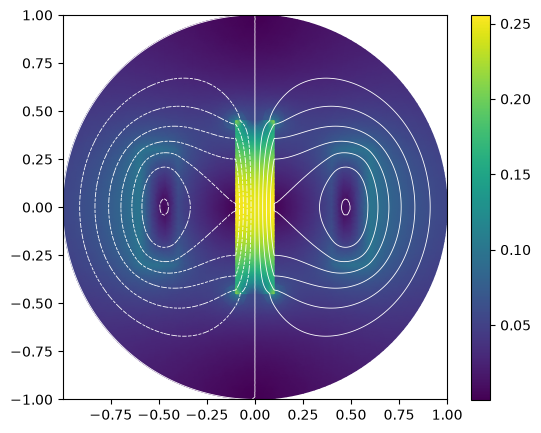

In [6]:
import matplotlib.pyplot as plt

from ngsufl.pyplot import tricontour, tripcolor

Bh = Function(VectorFunctionSpace(mesh, "DG", 2)).interpolate(B)
fig, axes = plt.subplots(figsize=(6.2, 5))
colors = tripcolor(Bh, axes=axes, num_sample_points=2, cmap="viridis")
fig.colorbar(colors)
tricontour(Az, levels=14, axes=axes, colors="w", linewidths=0.6)
axes.set_aspect("equal");

## Checks

The energy balance $\int \nu |\nabla A_z|^2 dx = \int J A_z\,dx$ holds exactly for the discrete
solution (test with $w=A_z$).  Second, the same problem is written directly in NGSolve with
`mesh.ngs` and compared. 

In [7]:
lhs_energy = assemble(sum(nu_r * dot(grad(Az), grad(Az)) * dx(name) for name, nu_r in nu.items()))
rhs_energy = assemble(Az * dx("coil_p") - Az * dx("coil_m"))
print("int nu |B|^2 :", lhs_energy)
print("int J A      :", rhs_energy)

import ngsolve as ngs
m = mesh.ngs
fes = ngs.H1(m, order=3, dirichlet="rim")
u_, v_ = fes.TnT()
nu_cf = m.MaterialCF(nu, default=1.0)
J_cf = m.MaterialCF({"coil_p": 1.0, "coil_m": -1.0}, default=0.0)
form = ngs.BilinearForm(nu_cf * ngs.grad(u_) * ngs.grad(v_) * ngs.dx).Assemble()
rhs = ngs.LinearForm(J_cf * v_ * ngs.dx).Assemble()
g = ngs.GridFunction(fes)
g.vec.data = form.mat.Inverse(fes.FreeDofs(), inverse="sparsecholesky") * rhs.vec
print("native NGSolve:", ngs.Integrate(J_cf * g, m), " dofs", fes.ndof, "vs", V.dim())
print("|| A_ngsufl - A_native ||_L2:", ngs.Integrate((Az.gf - g) ** 2, m) ** 0.5)

int nu |B|^2 : 0.0072264161049740705
int J A      : 0.00722641610497406
native NGSolve: 0.00722641610495293  dofs 8569 vs 8569
|| A_ngsufl - A_native ||_L2: 2.890055029201655e-11
